# netweave Real-Data Example: Charleston, SC

This notebook demonstrates a complete workflow using **real data**:

1. **Geographic boundary** from `geodatasets` (Charleston MSA census tracts)
2. **Transit network** from Transitland API (GTFS feeds)
3. **Pedestrian network** from OpenStreetMap via `osmnx`
4. **Integration** into a multimodal network for accessibility analysis

## Requirements

- `TRANSITLAND_API_KEY` environment variable (get one free at https://transit.land)
- `geodatasets` for sample boundary data
- `osmnx` for OSM downloading
- `pandarm` for network analysis (optional)

## API Overview

| Step | Function | Input | Output |
|------|----------|-------|--------|
| 1 | `geodatasets.get_path()` | dataset name | GeoPackage path |
| 2 | `gpd.read_file()` | path | GeoDataFrame |
| 3 | `search_feeds(polygon=gdf)` | GeoDataFrame | Feed metadata |
| 4 | `fetch_feeds()` | feed keys | GTFSFeed |
| 5 | `create_transit_network()` | GTFSFeed | TransitNetwork |
| 6 | `load_network_from_bbox()` | bbox | OSMNetwork |
| 7 | `create_osm_network()` | OSMNetwork | weighted OSMNetwork |
| 8 | `integrate()` | TransitNetwork + OSMNetwork or pandarm.Network | IntegratedNetwork |
| 9 | `to_pandarm()` | IntegratedNetwork | pandarm.Network |

In [1]:
%load_ext autoreload
%autoreload 2

import os

import geodatasets
import geopandas as gpd
import matplotlib.pyplot as plt

from netweave.gtfs.transitland import (
    fetch_feeds,
    search_feeds,
    transit_network_from_transitland,
)
from netweave.gtfs.network import create_transit_network
from netweave.osm import load_network_from_bbox, create_osm_network
from netweave.network import integrate, to_pandarm

# Optional: set your Transitland API key here or as env var
# os.environ["TRANSITLAND_API_KEY"] = "your-key-here"

print("Imports successful!")

Imports successful!


## 1. Load Geographic Boundary

We'll use the `geoda charleston1` dataset from `geodatasets` — a GeoPackage of census tracts for the Charleston, SC Metropolitan Statistical Area. This gives us a realistic boundary for querying transit feeds and OSM data.

Loaded 117 census tracts
CRS: EPSG:4326
Total bounds: [-80.791967  32.493208 -79.26914   33.507172]


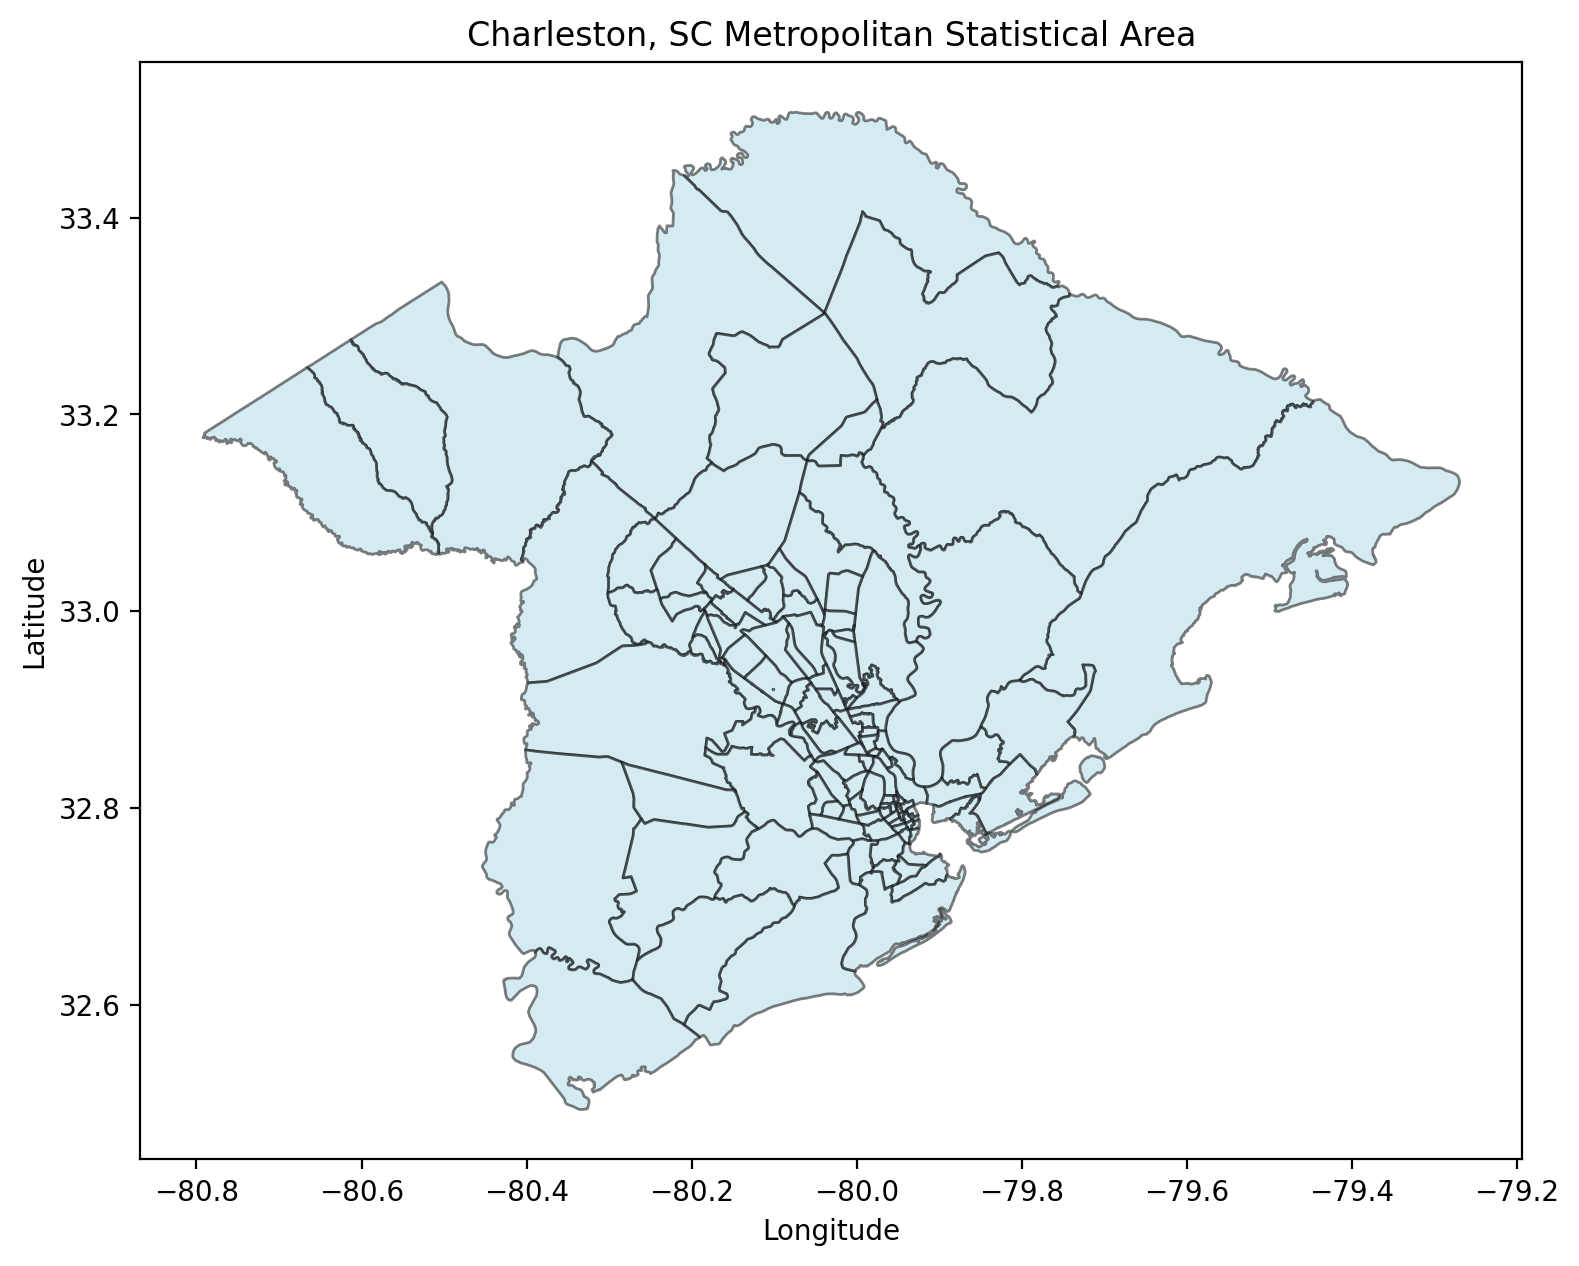

In [2]:
# Load Charleston MSA census tracts
path = geodatasets.get_path("geoda charleston1")
charleston_gdf = gpd.read_file(path)

print(f"Loaded {len(charleston_gdf)} census tracts")
print(f"CRS: {charleston_gdf.crs}")
print(f"Total bounds: {charleston_gdf.total_bounds}")

# Plot the boundary
fig, ax = plt.subplots(figsize=(8, 8))
charleston_gdf.plot(ax=ax, edgecolor="black", facecolor="lightblue", alpha=0.5)
ax.set_title("Charleston, SC Metropolitan Statistical Area")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

## 2. Search for GTFS Feeds on Transitland

Using the Charleston boundary, we query Transitland for GTFS feeds that serve this area. The `search_feeds()` function accepts a GeoDataFrame directly and computes the bounding box automatically.

**Note:** You need a free Transitland API key from https://transit.land. Set it as the `TRANSITLAND_API_KEY` environment variable or pass it directly.

In [3]:
# Search for GTFS feeds serving the Charleston area
# This requires a Transitland API key
feeds_df = search_feeds(
    polygon=charleston_gdf, limit=10, api_key='NpQXyLZi60tJpG8Oz6XACrs9o1LeDcKr'
)

print(f"Found {len(feeds_df)} GTFS feed(s)")
feeds_df[["feed_key", "name", "spec", "license_redistribution"]].head()

Found 8 feed(s) on Transitland
Found 8 GTFS feed(s)


,feed_key,name,spec,license_redistribution
0,359,NaN,GTFS,
1,531,NaN,GTFS,
2,2257,NaN,GTFS,
3,4303,NaN,GTFS,
4,4695,NaN,GTFS,


## 3. Download GTFS Feeds

Download the discovered feeds and merge them into a single `GTFSFeed`. The `fetch_feeds()` function handles downloading, validation, and merging automatically. Feeds that don't allow redistribution are skipped by default.

In [4]:
# Download and merge all discovered feeds (search + download in one step)

feed = fetch_feeds(
    polygon=charleston_gdf,
    limit=10,
    api_key='NpQXyLZi60tJpG8Oz6XACrs9o1LeDcKr',
    merge=True,
    skip_no_redistribution=False,  # Download all feeds, even if redistribution is not allowed
)

print(f"Merged feed: {len(feed.stops)} stops, {len(feed.routes)} routes, {len(feed.trips)} trips")
feed.stops.head()

Found 8 feed(s) on Transitland


Merged 8 feed(s) into a single GTFSFeed
Merged feed: 8692 stops, 1448 routes, 26212 trips


,stop_id,stop_code,stop_name,stop_desc,stop_lat,stop_lon,zone_id,stop_url,location_type,parent_station,stop_timezone,wheelchair_boarding,level_id,platform_code,position,direction,tts_stop_name
0,10123305,NaN,TidePointe,NaN,32.172932,-80.776353,NaN,NaN,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
1,10123306,NaN,Salty Dog T-Shirt Factory at Arrow Rd,NaN,32.165329,-80.76766,NaN,NaN,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
2,10123307,NaN,The Greenery Inc at Arrow Rd,NaN,32.162703,-80.765422,NaN,NaN,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
3,10123308,NaN,Weichert Realtors at Dunnagans Alley,NaN,32.157012,-80.762078,NaN,NaN,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN
4,10138090,NaN,Circle K at Pope Ave,NaN,32.14366,-80.752503,NaN,NaN,0,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN


## 4. Create Transit Network

Build a transit network from the merged GTFS feed for Monday service during the AM peak (7–10 AM). The `create_transit_network()` function selects active service IDs, filters stop times, and creates edges between consecutive stops weighted by travel time.

In [5]:
# Create transit network for Monday AM peak
transit = create_transit_network(
    feed=feed,
    day="monday",
    timerange=("07:00:00", "10:00:00"),
    prune=charleston_gdf
)

print(f"Transit network: {len(transit.nodes)} stops, {len(transit.edges)} edges")
transit.edges.head()

Selected 8430 active service ID(s)
Pruned to study area: 2208 stops, 27334 stop_times, 1366 trips, 38 routes
Dropped 1981 transit edges with non-positive weight (25968 → 23987)
Transit network: 984 nodes, 23987 edges
Transit network: 984 stops, 23987 edges


,from,to,weight,unique_trip_id,unique_route_id,route_type,geometry,net_type
0,f1_4250785,f1_2382773,0.733333,f1_t_5990003_b_84051_tn_0,f1_6299,3,"LINESTRING (-80.17583 33.02215, -80.17628 33.0...",transit
1,f1_2382773,f1_2382824,4.266667,f1_t_5990003_b_84051_tn_0,f1_6299,3,"LINESTRING (-80.17583 33.02215, -80.17628 33.0...",transit
2,f1_2382824,f1_2455619,7.000000,f1_t_5990003_b_84051_tn_0,f1_6299,3,"LINESTRING (-80.17583 33.02215, -80.17628 33.0...",transit
3,f1_2455619,f1_2455621,7.483333,f1_t_5990003_b_84051_tn_0,f1_6299,3,"LINESTRING (-80.17583 33.02215, -80.17628 33.0...",transit
4,f1_2455621,f1_2382779,7.516667,f1_t_5990003_b_84051_tn_0,f1_6299,3,"LINESTRING (-80.17583 33.02215, -80.17628 33.0...",transit


In [6]:
import geopandas as gpd
from geosnap.visualize import lbexplore
gpd.GeoDataFrame(transit.edges).lb.explore()

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/var/folders/j8/5bgcw6hs7cqcbbz48d6bsftw0000gp/T/ipykernel_63761/3114546371.py:2: UserWarning: This geopandas extension is experimental and untested; it will soon be replaced by another implementation in `lonboard`. See <https://github.com/developmentseed/lonboard/pull/860>
  from geosnap.visualize import lbexplore


## 5. Download OSM Pedestrian Network

Download the OpenStreetMap pedestrian network for the Charleston area using `osmnx`. The `load_network_from_bbox()` function handles the download and returns an `OSMNetwork` dataclass with nodes and edges.

In [7]:
import pandarm as pdna

ped_net = pdna.Network.from_gdf(charleston_gdf, twoway=False)

/Users/knaaptime/miniforge3/envs/netweave/lib/python3.14/site-packages/pandarm/loaders/osm.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  nodes["x"] = nodes.centroid.x
/Users/knaaptime/miniforge3/envs/netweave/lib/python3.14/site-packages/pandarm/loaders/osm.py:12: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  nodes["y"] = nodes.centroid.y


Generating contraction hierarchies with 16 threads.
Setting CH node vector of size 134915
Setting CH edge vector of size 362240
Range graph removed 374214 edges of 724480
. 10% . 20% . 30% . 40% . 50% . 60% . 70% . 80% . 90% . 100%


In [8]:
ped_net = pdna.Network.from_gdf(charleston_gdf, twoway=False)

/Users/knaaptime/miniforge3/envs/netweave/lib/python3.14/site-packages/pandarm/loaders/osm.py:11: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  nodes["x"] = nodes.centroid.x
/Users/knaaptime/miniforge3/envs/netweave/lib/python3.14/site-packages/pandarm/loaders/osm.py:12: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  nodes["y"] = nodes.centroid.y


Generating contraction hierarchies with 16 threads.
Setting CH node vector of size 134915
Setting CH edge vector of size 362240
Range graph removed 374214 edges of 724480
. 10% . 20% . 30% . 40% . 50% . 60% . 70% . 80% . 90% . 100%


## 6. Integrate Transit + Pedestrian Networks

Combine the transit and OSM networks by creating connector edges between transit stops and the nearest OSM nodes. The `integrate()` function uses a cKDTree for fast nearest-neighbor lookup and weights connectors by walking time.

In [9]:
# Integrate transit + OSM networks
integrated = integrate(
    transit=transit,
    osm=ped_net,
    max_connector_dist=500.0,  # meters
    walk_speed_mph=3.0,
)

print(f"Integrated network: {len(integrated.nodes)} nodes, {len(integrated.edges)} edges")
print(f"  - Transit edges: {len(integrated.transit_edges)}")
print(f"  - OSM edges: {len(integrated.osm_edges)}")
print(f"  - Connector edges: {len(integrated.connector_edges)}")

# Show edge breakdown
integrated.edges["net_type"].value_counts()

Built 1968 connector edges for 984 stops
Integrated network: 135899 nodes, 388195 edges (1968 connectors)
Integrated network: 135899 nodes, 388195 edges
  - Transit edges: 23987
  - OSM edges: 362240
  - Connector edges: 1968


net_type
transit           23987
transit to osm      984
osm to transit      984
Name: count, dtype: int64

## 7. Visualize the Integrated Network

Plot the transit stops, OSM nodes, and connector edges on a map. This gives a sense of how well the transit network connects to the pedestrian street network.

## 8. Convert to pandarm Network (Optional)

If you have `pandarm` installed, you can convert the integrated network directly to a `pandarm.Network` for accessibility analysis (e.g., cumulative accessibility, nearest POIs).

In [10]:
net = to_pandarm(integrated)

# to_pandarm remaps node IDs to contiguous integers for pandarm compatibility.
# The mapping from original IDs to remapped IDs is stored in the nodes DataFrame:
print(f"pandarm.Network: {len(net.node_ids)} nodes, {len(net.edges_df)} edges")
print(f"Weight range: {net.edges_df['weight'].min():.2f} – {net.edges_df['weight'].max():.2f} minutes")

Building pandarm.Network with 135899 nodes and 388195 edges


/Users/knaaptime/Dropbox/projects/netweave/netweave/network/pandarm.py:85: UserWarning: No CRS was passed to geometry input; assuming geographic coordinates
  return pandarm.Network(


Generating contraction hierarchies with 16 threads.
Setting CH node vector of size 135899
Setting CH edge vector of size 388195
Range graph removed 421928 edges of 776390
. 10% . 20% . 30% . 40% . 50% . 60% . 70% . 80% . 90% . 100%
pandarm.Network: 135899 nodes, 388195 edges
Weight range: 0.00 – 86.91 minutes


In [11]:
net.edges_df.lb.explore()

In [12]:
net.edges_df.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 388195 entries, 0 to 388194
Data columns (total 4 columns):
 #   Column    Non-Null Count   Dtype   
---  ------    --------------   -----   
 0   from      388195 non-null  int64   
 1   to        388195 non-null  int64   
 2   weight    388195 non-null  float64 
 3   geometry  388195 non-null  geometry
dtypes: float64(1), geometry(1), int64(2)
memory usage: 11.8 MB


In [13]:
net.edges_df.weight

0         0.733333
1         4.266667
2         7.000000
3         7.483333
4         7.516667
            ...   
388190    1.062526
388191    0.268665
388192    0.150999
388193    0.009730
388194    0.402457
Name: weight, Length: 388195, dtype: float64

In [ ]:
# precompute the network for accessibility queries (max distance in minutes)
# this takes 1.5 mins on my m3 max
# (you dont actually need to precompute; getting nodes from one origin is fast even at large scales)

net.precompute(45)

In [27]:
net.nodes_df.loc[net.nodes_in_range([390312], 45).destination.tolist()].lb.explore()